# Understanding the airport weather forecast data

This dataset contains archived airport weather forecasts (Terminal Aerodrome Forecasts, or TAFs) from the Iowa Environmental Mesonet (IEM) AFOS archive. Each bulletin is issued for an airport at a specific UTC time and divides the upcoming forecast window into time segments describing expected cloud ceilings, horizontal visibility, and hazardous conditions such as thunderstorms, freezing precipitation, low-level wind shear, and instrument flight rules (IFR).

In this notebook, we inspect the raw forecast bulletins and focus on the main parsed fields: `station`, `issue`, `segment_start`, `segment_end`, `ceiling_m`, `visibility_km`, `ifr`, `thunderstorm`, `freezing_precip`, and `wind_shear`. In the modeling pipeline, each flight is matched—using only bulletins issued at or before scheduled departure—to the forecast segment covering its scheduled arrival time at the destination airport (or a nearby fallback station within 50 NM) to build destination forecast features and measure expected ceiling deterioration relative to departure-time destination observations.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import re
import sys
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Show every column and keep the full text in tables.
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.max_colwidth', None)

root = Path.cwd().resolve()
if not (root / 'config.json').is_file():
    root = root.parent
if not (root / 'config.json').is_file():
    raise FileNotFoundError('Run from the project root or notebooks directory.')
sys.path.insert(0, str(root))

from scripts.common.config import load_config, project_path
from scripts.enroute_weather import clean_taf

_, _, config = load_config(root)
forecast_dir = project_path(root, config['datasets']['taf']['bronze_directory'])
zip_files = sorted(forecast_dir.glob('*.zip'))
if not zip_files:
    raise FileNotFoundError('No local forecast ZIP archives were found.')

## Sample of raw forecast bulletins

In [2]:
raw_samples = []
with ZipFile(zip_files[0]) as archive:
    for member in [m for m in archive.infolist() if not m.is_dir()][:3]:
        raw_samples.append({
            'archive': zip_files[0].name,
            'member': member.filename,
            'text': archive.read(member).decode('utf-8', errors='replace').strip(),
        })
pd.DataFrame(raw_samples)

,archive,member,text
0,20231230-20240101-3db71b3d9785.zip,TAFJSJ_202312312347.txt,936 \nFTUS42 TJSJ 312347\nTAFJSJ\nTAF\nTJSJ 312347Z 0100/0124 10005KT P6SM FEW025 SCT040 SCT080\n TEMPO 0104/0105 2SM FU FEW020 SCT030\n FM011000 VRB05KT P6SM VCSH FEW025 SCT040\n FM011400 07012KT P6SM VCSH SCT025 BKN040\n FM012300 09007KT P6SM FEW025 SCT040 SCT060=
1,20231230-20240101-3db71b3d9785.zip,TAFSJC_202312312336.txt,116 \nFTUS46 KMTR 312336\nTAFSJC\nTAF\nKSJC 312336Z 0100/0124 14005KT P6SM FEW010 BKN050\n FM010100 VRB05KT P6SM VCSH OVC050\n FM011200 VRB03KT P6SM SCT050\n FM012000 31005KT P6SM BKN250=
2,20231230-20240101-3db71b3d9785.zip,TAFSMF_202312312336.txt,736 \nFTUS46 KSTO 312336\nTAFSMF\nTAF\nKSMF 312336Z 0100/0124 VRB03KT P6SM SCT035\n FM010100 35003KT P6SM SCT015 BKN050 OVC100\n FM010700 33005KT 3SM BR BKN003\n FM011000 33005KT 1/4SM FG VV003\n FM011800 33004KT 3SM BR BKN005\n FM012000 31004KT P6SM BKN250=


## Fields we keep

In [3]:
column_details = [
    ('station', 'ICAO airport station code from the forecast header'),
    ('product', 'Archived bulletin filename'),
    ('issue', 'Forecast issue time (UTC epoch seconds)'),
    ('segment_start', 'Forecast segment start time (UTC epoch seconds)'),
    ('segment_end', 'Forecast segment end time (UTC epoch seconds)'),
    ('ifr', 'Instrument flight rules flag (ceiling < 1000 ft or visibility < 3 mi)'),
    ('thunderstorm', 'Thunderstorm or cumulonimbus forecast flag'),
    ('freezing_precip', 'Freezing rain, ice pellets, or heavy snow forecast flag'),
    ('wind_shear', 'Low-level wind shear forecast flag'),
    ('ceiling_m', 'Lowest broken, overcast, or vertical-visibility ceiling in metres'),
    ('visibility_km', 'Forecast prevailing visibility in kilometres'),
]
pd.DataFrame(column_details, columns=['column', 'meaning'])

,column,meaning
0,station,ICAO airport station code from the forecast header
1,product,Archived bulletin filename
2,issue,Forecast issue time (UTC epoch seconds)
3,segment_start,Forecast segment start time (UTC epoch seconds)
4,segment_end,Forecast segment end time (UTC epoch seconds)
5,ifr,Instrument flight rules flag (ceiling < 1000 ft or visibility < 3 mi)
6,thunderstorm,Thunderstorm or cumulonimbus forecast flag
7,freezing_precip,"Freezing rain, ice pellets, or heavy snow forecast flag"
8,wind_shear,Low-level wind shear forecast flag
9,ceiling_m,"Lowest broken, overcast, or vertical-visibility ceiling in metres"


## Sample of parsed forecast segments

In [4]:
sample_rows = []
with ZipFile(zip_files[0]) as archive:
    for member in [m for m in archive.infolist() if not m.is_dir()][:5]:
        ts = re.search(r'(?<!\d)(\d{12})(?!\d)', member.filename)
        published = datetime.strptime(ts[1], '%Y%m%d%H%M').replace(tzinfo=timezone.utc)
        sample_rows.extend(clean_taf.parse_taf(
            archive.read(member).decode('utf-8', errors='replace'), published, member.filename
        ))
sample_cols = [name for name, _ in column_details]
sample_df = pd.DataFrame(sample_rows, columns=sample_cols)
for col in ('issue', 'segment_start', 'segment_end'):
    sample_df[col] = pd.to_datetime(sample_df[col], unit='s', utc=True)
sample_df.head(10)

,station,product,issue,segment_start,segment_end,ifr,thunderstorm,freezing_precip,wind_shear,ceiling_m,visibility_km
0,TJSJ,TAFJSJ_202312312347.txt,2023-12-31 23:47:00+00:00,2024-01-01 00:00:00+00:00,2024-01-01 04:00:00+00:00,0,0,0,0,NaN,9.656064
1,TJSJ,TAFJSJ_202312312347.txt,2023-12-31 23:47:00+00:00,2024-01-01 04:00:00+00:00,2024-01-01 05:00:00+00:00,1,0,0,0,NaN,3.218688
2,TJSJ,TAFJSJ_202312312347.txt,2023-12-31 23:47:00+00:00,2024-01-01 05:00:00+00:00,2024-01-01 10:00:00+00:00,0,0,0,0,NaN,9.656064
3,TJSJ,TAFJSJ_202312312347.txt,2023-12-31 23:47:00+00:00,2024-01-01 10:00:00+00:00,2024-01-01 14:00:00+00:00,0,0,0,0,NaN,9.656064
4,TJSJ,TAFJSJ_202312312347.txt,2023-12-31 23:47:00+00:00,2024-01-01 14:00:00+00:00,2024-01-01 23:00:00+00:00,0,0,0,0,1219.2,9.656064
5,TJSJ,TAFJSJ_202312312347.txt,2023-12-31 23:47:00+00:00,2024-01-01 23:00:00+00:00,2024-01-02 00:00:00+00:00,0,0,0,0,NaN,9.656064
6,KSJC,TAFSJC_202312312336.txt,2023-12-31 23:36:00+00:00,2024-01-01 00:00:00+00:00,2024-01-01 01:00:00+00:00,0,0,0,0,1524.0,9.656064
7,KSJC,TAFSJC_202312312336.txt,2023-12-31 23:36:00+00:00,2024-01-01 01:00:00+00:00,2024-01-01 12:00:00+00:00,0,0,0,0,1524.0,9.656064
8,KSJC,TAFSJC_202312312336.txt,2023-12-31 23:36:00+00:00,2024-01-01 12:00:00+00:00,2024-01-01 20:00:00+00:00,0,0,0,0,NaN,9.656064
9,KSJC,TAFSJC_202312312336.txt,2023-12-31 23:36:00+00:00,2024-01-01 20:00:00+00:00,2024-01-02 00:00:00+00:00,0,0,0,0,7620.0,9.656064


## Loading the forecast data

In [5]:
# Read one ZIP archive at a time to parse forecast segments and track raw bulletin counts.
bulletin_counts = Counter()
parsed_rows = []
sample_cols = [name for name, _ in column_details]

for path in zip_files:
    with ZipFile(path) as archive:
        for member in archive.infolist():
            if member.is_dir():
                continue
            bulletin_counts['total_bulletins'] += 1
            match = re.search(r'(?<!\d)(\d{12})(?!\d)', member.filename)
            if not match:
                bulletin_counts['unexpected_member'] += 1
                continue
            published = datetime.strptime(match[1], '%Y%m%d%H%M').replace(tzinfo=timezone.utc)
            text = archive.read(member).decode('utf-8', errors='replace')
            try:
                rows = clean_taf.parse_taf(text, published, member.filename)
            except ValueError:
                bulletin_counts['malformed_bulletins'] += 1
                continue
            if len(rows) == 1 and rows[0][5] is None and re.search(r'\b(?:CNL|NIL)\b', text.upper()):
                bulletin_counts['cancelled_or_nil'] += 1
            else:
                bulletin_counts['valid_bulletins'] += 1
            parsed_rows.extend(rows)

forecasts = pd.DataFrame(parsed_rows, columns=sample_cols)
forecasts['issue_utc'] = pd.to_datetime(forecasts['issue'], unit='s', utc=True)
forecasts['duration_hours'] = (forecasts['segment_end'] - forecasts['segment_start']) / 3600.0
del parsed_rows

## Dataset size and date range

In [6]:
pd.Series({
    'ZIP archives': len(zip_files),
    'Raw bulletin files': bulletin_counts['total_bulletins'],
    'Valid bulletins': bulletin_counts['valid_bulletins'],
    'Cancelled or NIL bulletins': bulletin_counts['cancelled_or_nil'],
    'Malformed bulletins skipped': bulletin_counts['malformed_bulletins'],
    'Parsed forecast segments': len(forecasts),
    'Stations': forecasts['station'].nunique(),
    'First issue timestamp (UTC)': forecasts['issue_utc'].min(),
    'Last issue timestamp (UTC)': forecasts['issue_utc'].max(),
}, name='value').to_frame()

,value
ZIP archives,45
Raw bulletin files,166863
Valid bulletins,166861
Cancelled or NIL bulletins,0
Malformed bulletins skipped,2
Parsed forecast segments,763959
Stations,50
First issue timestamp (UTC),2023-12-30 00:02:00+00:00
Last issue timestamp (UTC),2025-02-01 23:46:00+00:00


## Duplicate forecast segments

In [7]:
pd.Series({
    'Duplicate full rows': int(forecasts.duplicated(subset=sample_cols).sum()),
    'Duplicate (station, product, segment_start, segment_end)': int(
        forecasts.duplicated(subset=['station', 'product', 'segment_start', 'segment_end']).sum()
    ),
}, name='count').to_frame()

,count
Duplicate full rows,939
"Duplicate (station, product, segment_start, segment_end)",1039


## Summary statistics

In [8]:
numeric_cols = ['ceiling_m', 'visibility_km', 'duration_hours']
forecasts[numeric_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
ceiling_m,439583.0,1853.768,2212.676,0.000,457.200,914.400,1828.800,18288.000
visibility_km,763953.0,9.052,1.736,0.000,9.656,9.656,9.656,9.656
duration_hours,763959.0,6.008,4.220,0.017,3.000,5.000,8.000,30.000


## Missing and non-numeric values

In [9]:
# Ceiling is null for clear-sky groups (SKC/CLR/FEW/SCT) as well as CNL/NIL or omitted heights.
check_cols = ['ifr', 'thunderstorm', 'freezing_precip', 'wind_shear', 'ceiling_m', 'visibility_km']
valid_counts = forecasts[check_cols].count()
missing_counts = len(forecasts) - valid_counts
pd.DataFrame({
    'valid_values': valid_counts,
    'missing_values': missing_counts,
    'missing_percent': (100 * missing_counts / len(forecasts)).round(2),
})

,valid_values,missing_values,missing_percent
ifr,763952,7,0.00
thunderstorm,763959,0,0.00
freezing_precip,763959,0,0.00
wind_shear,763959,0,0.00
ceiling_m,439583,324376,42.46
visibility_km,763953,6,0.00


## Forecast condition and hazard rates

,count_1,count_0,missing,positive_percent_of_valid
ifr,81062,682890,7,10.61
thunderstorm,39808,724151,0,5.21
freezing_precip,1248,762711,0,0.16
wind_shear,8810,755149,0,1.15


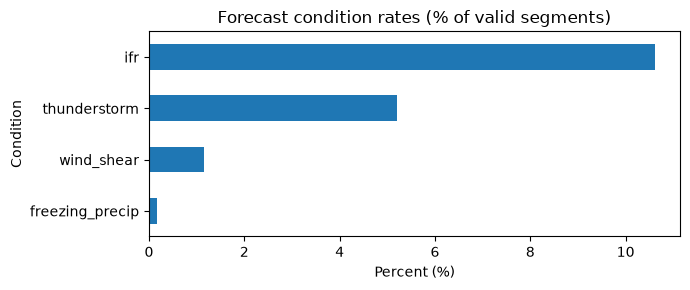

In [10]:
flag_cols = ['ifr', 'thunderstorm', 'freezing_precip', 'wind_shear']
flag_summary = pd.DataFrame({
    'count_1': [int((forecasts[col] == 1).sum()) for col in flag_cols],
    'count_0': [int((forecasts[col] == 0).sum()) for col in flag_cols],
    'missing': [int(forecasts[col].isna().sum()) for col in flag_cols],
    'positive_percent_of_valid': [round(100 * forecasts[col].dropna().mean(), 2) for col in flag_cols],
}, index=flag_cols)
display(flag_summary)

ax = flag_summary['positive_percent_of_valid'].sort_values().plot.barh(figsize=(7, 3))
ax.set(title='Forecast condition rates (% of valid segments)', xlabel='Percent (%)', ylabel='Condition')
plt.tight_layout()
plt.show()

## Distribution of ceiling height

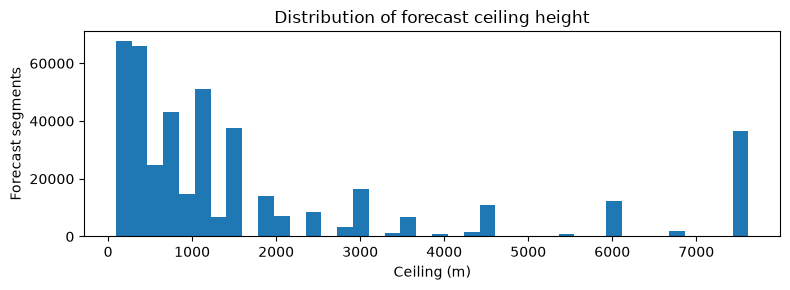

In [11]:
# Show the middle 98% of numeric values for readability; the summary table keeps the full range.
values = forecasts['ceiling_m'].dropna()
low, high = values.quantile([0.01, 0.99])
ax = values[values.between(low, high)].plot.hist(bins=40, figsize=(8, 3))
ax.set(title='Distribution of forecast ceiling height', xlabel='Ceiling (m)', ylabel='Forecast segments')
plt.tight_layout()
plt.show()

## Distribution of visibility

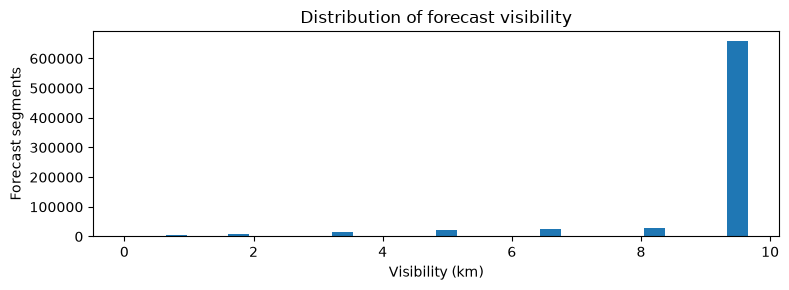

In [12]:
values = forecasts['visibility_km'].dropna()
ax = values.plot.hist(bins=30, figsize=(8, 3))
ax.set(title='Distribution of forecast visibility', xlabel='Visibility (km)', ylabel='Forecast segments')
plt.tight_layout()
plt.show()

## Distribution of forecast segment duration

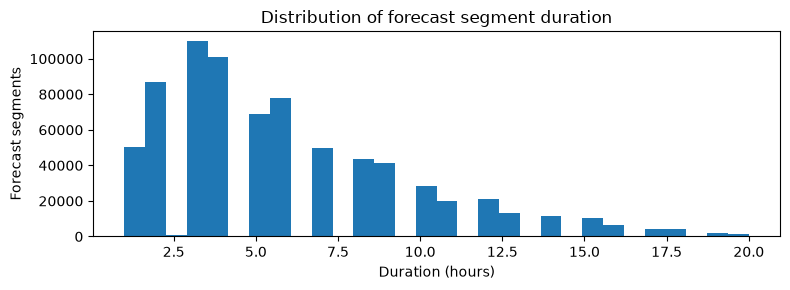

In [13]:
values = forecasts['duration_hours'].dropna()
low, high = values.quantile([0.01, 0.99])
ax = values[values.between(low, high)].plot.hist(bins=30, figsize=(8, 3))
ax.set(title='Distribution of forecast segment duration', xlabel='Duration (hours)', ylabel='Forecast segments')
plt.tight_layout()
plt.show()

## Top stations by forecast segment count

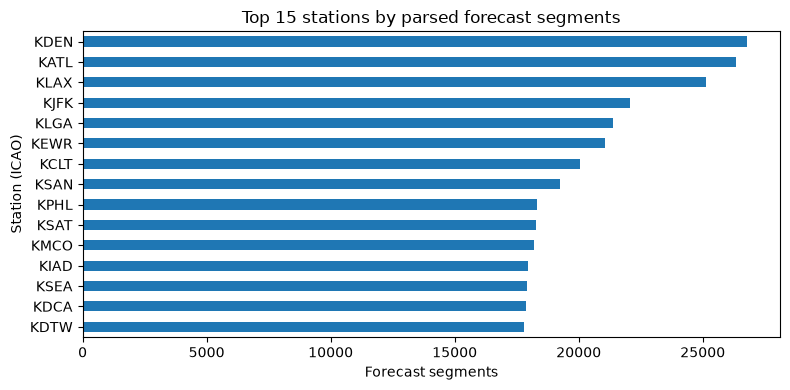

In [14]:
ax = forecasts['station'].value_counts().head(15).sort_values().plot.barh(figsize=(8, 4))
ax.set(title='Top 15 stations by parsed forecast segments', xlabel='Forecast segments', ylabel='Station (ICAO)')
plt.tight_layout()
plt.show()

## Data source
Archived airport forecast bulletins are retrieved from the [Iowa Environmental Mesonet (IEM) AFOS archive](https://mesonet.agron.iastate.edu/nws/text.php).